In [5]:
import sys
!{sys.executable} -m pip install xgboost imbalanced-learn

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)


In [ ]:
import xgboost
import imblearn

print("XGBoost version:", xgboost.__version__)
print("Imbalanced-learn version:", imblearn.__version__)
print("Libraries installed successfully!")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("cs-training.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [5]:
df = pd.read_csv("cs-training.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [6]:
print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

DATASET INFORMATION

Shape:
(150000, 12)

Columns:
['Unnamed: 0', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Data types:
Unnamed: 0                                int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

First 5 rows:


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [7]:
if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"], inplace=True)

print("Shape after removing unnecessary column:")
print(df.shape)

Shape after removing unnecessary column:
(150000, 11)


In [8]:
TARGET = "SeriousDlqin2yrs"

print("Target distribution:")
print(df[TARGET].value_counts())

print("\nTarget percentage:")
print(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Target percentage:
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64


In [10]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing = missing.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing)

,Missing Count,Missing Percentage
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62
SeriousDlqin2yrs,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
DebtRatio,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
NumberOfTimes90DaysLate,0,0.00
NumberRealEstateLoansOrLines,0,0.00


In [11]:
print("Number of duplicate rows:")

print(df.duplicated().sum())

Number of duplicate rows:
609


In [12]:
df = df.drop_duplicates()

print("Shape after removing duplicates:")
print(df.shape)

Shape after removing duplicates:
(149391, 11)


In [13]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,149391.0,0.066999,0.250021,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,149391.0,6.071087,250.263672,0.0,0.030132,0.154235,0.556494,50708.0
age,149391.0,52.306237,14.725962,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,149391.0,0.393886,3.852953,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,149391.0,354.436740,2041.843455,0.0,0.177441,0.368234,0.875279,329664.0
MonthlyIncome,120170.0,6675.098269,14389.582246,0.0,3400.000000,5400.000000,8250.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,149391.0,8.480892,5.136515,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,149391.0,0.238120,3.826165,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,149391.0,1.022391,1.130196,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,149391.0,0.212503,3.810523,0.0,0.000000,0.000000,0.000000,98.0


In [14]:
# Age cannot realistically be 0
df.loc[df["age"] <= 0, "age"] = np.nan

# Monthly income <= 0 is treated as missing
df.loc[df["MonthlyIncome"] <= 0, "MonthlyIncome"] = np.nan

# Number of dependents cannot be negative
df.loc[
    df["NumberOfDependents"] < 0,
    "NumberOfDependents"
] = np.nan

print("Invalid values handled.")

Invalid values handled.


In [15]:
df["income_per_dependent"] = (
    df["MonthlyIncome"] /
    (df["NumberOfDependents"].fillna(0) + 1)
)

In [16]:
df["total_delinquency"] = (
    df["NumberOfTime30-59DaysPastDueNotWorse"] +
    df["NumberOfTime60-89DaysPastDueNotWorse"] +
    df["NumberOfTimes90DaysLate"]
)

In [17]:
df["severe_delinquency"] = (
    df["NumberOfTimes90DaysLate"] +
    df["NumberOfTime60-89DaysPastDueNotWorse"]
)

In [18]:
df["recent_delinquency"] = (
    df["NumberOfTime30-59DaysPastDueNotWorse"] +
    df["NumberOfTime60-89DaysPastDueNotWorse"]
)

In [19]:
df["credit_utilization_risk"] = (
    df["RevolvingUtilizationOfUnsecuredLines"]
)

# Remove extremely large outliers
df["credit_utilization_risk"] = (
    df["credit_utilization_risk"].clip(
        lower=0,
        upper=2
    )
)

In [20]:
df["credit_lines_per_age"] = (
    df["NumberOfOpenCreditLinesAndLoans"] /
    df["age"].clip(lower=18)
)

In [21]:
df["real_estate_loan_ratio"] = (
    df["NumberRealEstateLoansOrLines"] /
    (
        df["NumberOfOpenCreditLinesAndLoans"] + 1
    )
)

In [22]:
df["debt_burden"] = (
    df["DebtRatio"] *
    df["MonthlyIncome"]
)

In [23]:
df["financial_stress_score"] = (
    df["DebtRatio"].clip(upper=5)
    +
    df["RevolvingUtilizationOfUnsecuredLines"].clip(
        upper=2
    )
    +
    df["total_delinquency"]
)

In [24]:
df["age_income_interaction"] = (
    df["age"] *
    np.log1p(
        df["MonthlyIncome"].fillna(
            df["MonthlyIncome"].median()
        )
    )
)

In [25]:
new_features = [
    "income_per_dependent",
    "total_delinquency",
    "severe_delinquency",
    "recent_delinquency",
    "credit_utilization_risk",
    "credit_lines_per_age",
    "real_estate_loan_ratio",
    "debt_burden",
    "financial_stress_score",
    "age_income_interaction"
]

display(
    df[new_features].head()
)

,income_per_dependent,total_delinquency,severe_delinquency,recent_delinquency,credit_utilization_risk,credit_lines_per_age,real_estate_loan_ratio,debt_burden,financial_stress_score,age_income_interaction
0,3040.0,2,0,2,0.766127,0.288889,0.428571,7323.197016,3.569109,410.325063
1,1300.0,0,0,0,0.957151,0.100000,0.000000,316.878123,1.079027,314.546051
2,3042.0,2,1,1,0.658180,0.052632,0.000000,258.914887,2.743294,304.782768
3,3300.0,0,0,0,0.233810,0.166667,0.000000,118.963951,0.269859,243.059422
4,63588.0,1,0,1,0.907239,0.142857,0.125000,1584.975094,1.932165,541.949593


In [26]:
FEATURES = [

    # Original Kaggle features
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",

    # Engineered features
    "income_per_dependent",
    "total_delinquency",
    "severe_delinquency",
    "recent_delinquency",
    "credit_utilization_risk",
    "credit_lines_per_age",
    "real_estate_loan_ratio",
    "debt_burden",
    "financial_stress_score",
    "age_income_interaction"
]

X = df[FEATURES]
y = df[TARGET]

print("Number of features:", len(FEATURES))

print("\nFeatures:")
for i, feature in enumerate(FEATURES, start=1):
    print(i, feature)

Number of features: 20

Features:
1 RevolvingUtilizationOfUnsecuredLines
2 age
3 DebtRatio
4 MonthlyIncome
5 NumberOfOpenCreditLinesAndLoans
6 NumberOfTimes90DaysLate
7 NumberRealEstateLoansOrLines
8 NumberOfTime30-59DaysPastDueNotWorse
9 NumberOfTime60-89DaysPastDueNotWorse
10 NumberOfDependents
11 income_per_dependent
12 total_delinquency
13 severe_delinquency
14 recent_delinquency
15 credit_utilization_risk
16 credit_lines_per_age
17 real_estate_loan_ratio
18 debt_burden
19 financial_stress_score
20 age_income_interaction


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

Training samples: 119512
Testing samples: 29879

Training target distribution:
SeriousDlqin2yrs
0    111505
1      8007
Name: count, dtype: int64


In [28]:
imputer = SimpleImputer(
    strategy="median"
)

X_train_imputed = imputer.fit_transform(
    X_train
)

X_test_imputed = imputer.transform(
    X_test
)

print("Missing values handled successfully.")

Missing values handled successfully.


In [29]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_imputed
)

X_test_scaled = scaler.transform(
    X_test_imputed
)

print("Feature scaling completed.")

Feature scaling completed.


In [30]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_imputed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
SeriousDlqin2yrs
0    111505
1      8007
Name: count, dtype: int64

After SMOTE:
SeriousDlqin2yrs
0    111505
1    111505
Name: count, dtype: int64


In [31]:
def evaluate_model(
    model_name,
    y_true,
    predictions,
    probabilities
):

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        f"Accuracy  : {accuracy:.4f}"
    )

    print(
        f"Precision : {precision:.4f}"
    )

    print(
        f"Recall    : {recall:.4f}"
    )

    print(
        f"F1 Score  : {f1:.4f}"
    )

    print(
        f"ROC-AUC   : {roc_auc:.4f}"
    )

    print("\nConfusion Matrix:")

    cm = confusion_matrix(
        y_true,
        predictions
    )

    print(cm)

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            predictions,
            zero_division=0
        )
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

In [32]:
print("=" * 70)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 70)

logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

lr_predictions = logistic_model.predict(
    X_test_scaled
)

lr_probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions,
    lr_probabilities
)

TRAINING LOGISTIC REGRESSION

Logistic Regression
Accuracy  : 0.7742
Precision : 0.1948
Recall    : 0.7562
F1 Score  : 0.3098
ROC-AUC   : 0.8406

Confusion Matrix:
[[21619  6258]
 [  488  1514]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87     27877
           1       0.19      0.76      0.31      2002

    accuracy                           0.77     29879
   macro avg       0.59      0.77      0.59     29879
weighted avg       0.93      0.77      0.83     29879



In [33]:
print("=" * 70)
print("TRAINING RANDOM FOREST")
print("=" * 70)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_smote,
    y_train_smote
)

rf_predictions = rf_model.predict(
    X_test_imputed
)

rf_probabilities = rf_model.predict_proba(
    X_test_imputed
)[:, 1]

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)

TRAINING RANDOM FOREST

Random Forest
Accuracy  : 0.9265
Precision : 0.4439
Recall    : 0.3811
F1 Score  : 0.4101
ROC-AUC   : 0.8545

Confusion Matrix:
[[26921   956]
 [ 1239   763]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     27877
           1       0.44      0.38      0.41      2002

    accuracy                           0.93     29879
   macro avg       0.70      0.67      0.69     29879
weighted avg       0.92      0.93      0.92     29879



In [34]:
print("=" * 70)
print("TRAINING XGBOOST")
print("=" * 70)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_smote,
    y_train_smote
)

xgb_predictions = xgb_model.predict(
    X_test_imputed
)

xgb_probabilities = xgb_model.predict_proba(
    X_test_imputed
)[:, 1]

xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    xgb_predictions,
    xgb_probabilities
)

TRAINING XGBOOST

XGBoost
Accuracy  : 0.9350
Precision : 0.5325
Recall    : 0.2453
F1 Score  : 0.3358
ROC-AUC   : 0.8598

Confusion Matrix:
[[27446   431]
 [ 1511   491]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97     27877
           1       0.53      0.25      0.34      2002

    accuracy                           0.94     29879
   macro avg       0.74      0.61      0.65     29879
weighted avg       0.92      0.94      0.92     29879



In [41]:
results = pd.DataFrame([
    lr_results,
    rf_results,
    xgb_results
])

results = results.sort_values(
    by="ROC-AUC",
    ascending=False
)

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    results.style
    .format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.9350,0.5325,0.2453,0.3358,0.8598
1,Random Forest,0.9265,0.4439,0.3811,0.4101,0.8545
0,Logistic Regression,0.7742,0.1948,0.7562,0.3098,0.8406


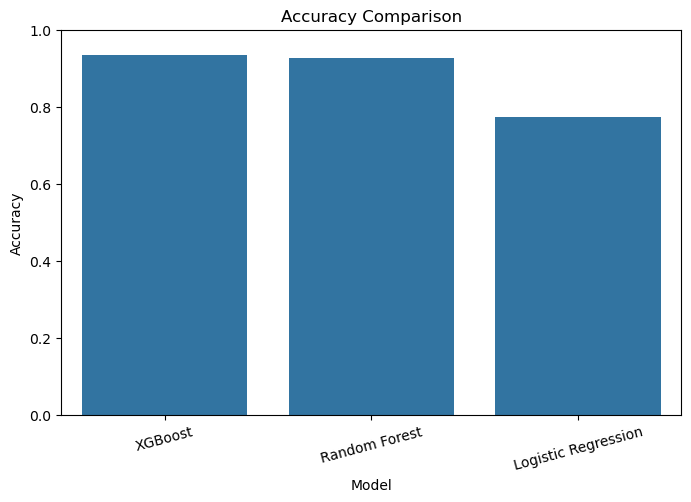

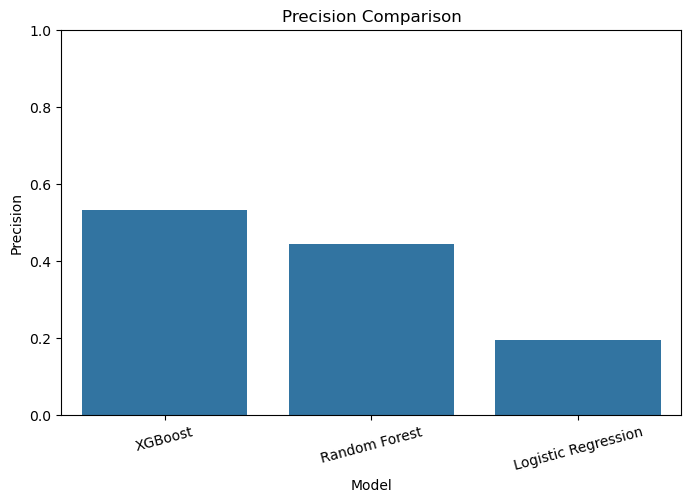

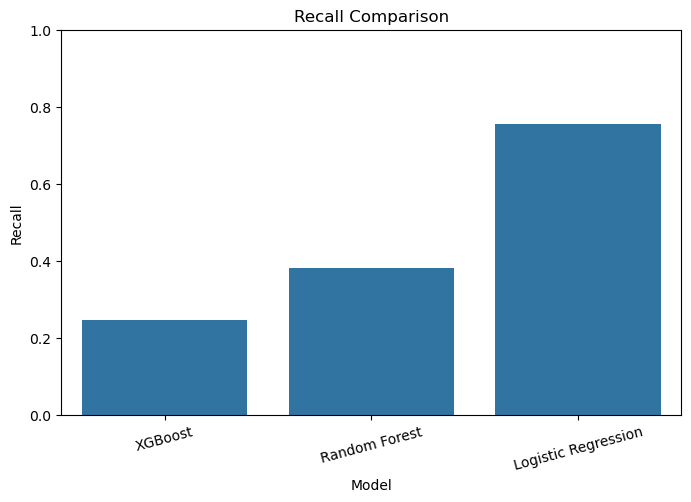

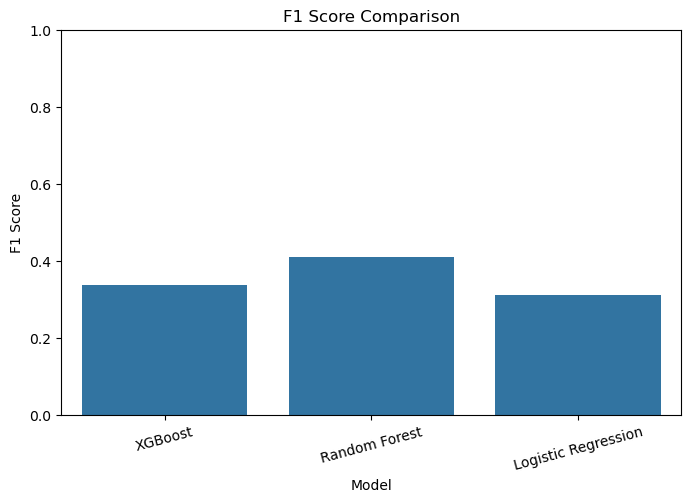

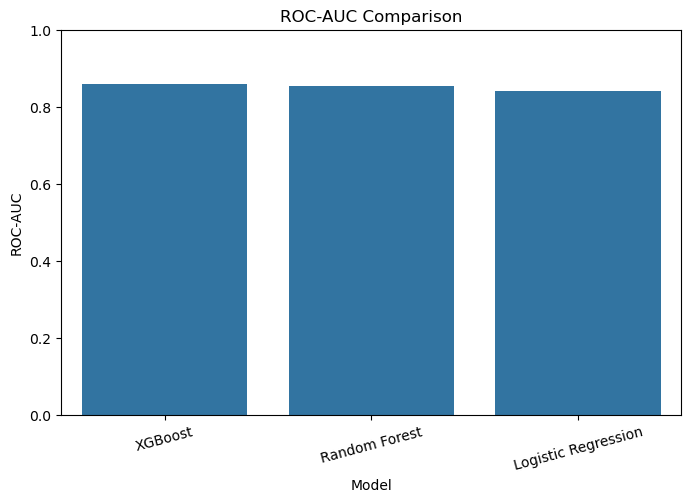

In [40]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=results,
        x="Model",
        y=metric
    )

    plt.title(
        f"{metric} Comparison"
    )

    plt.xticks(
        rotation=15
    )

    plt.ylim(0, 1)

    plt.show()

In [42]:
feature_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(
    feature_importance
)

,Feature,Importance
11,total_delinquency,0.254832
13,recent_delinquency,0.169347
12,severe_delinquency,0.131998
7,NumberOfTime30-59DaysPastDueNotWorse,0.107624
5,NumberOfTimes90DaysLate,0.073420
0,RevolvingUtilizationOfUnsecuredLines,0.053173
14,credit_utilization_risk,0.046796
18,financial_stress_score,0.036016
8,NumberOfTime60-89DaysPastDueNotWorse,0.028030
6,NumberRealEstateLoansOrLines,0.025606


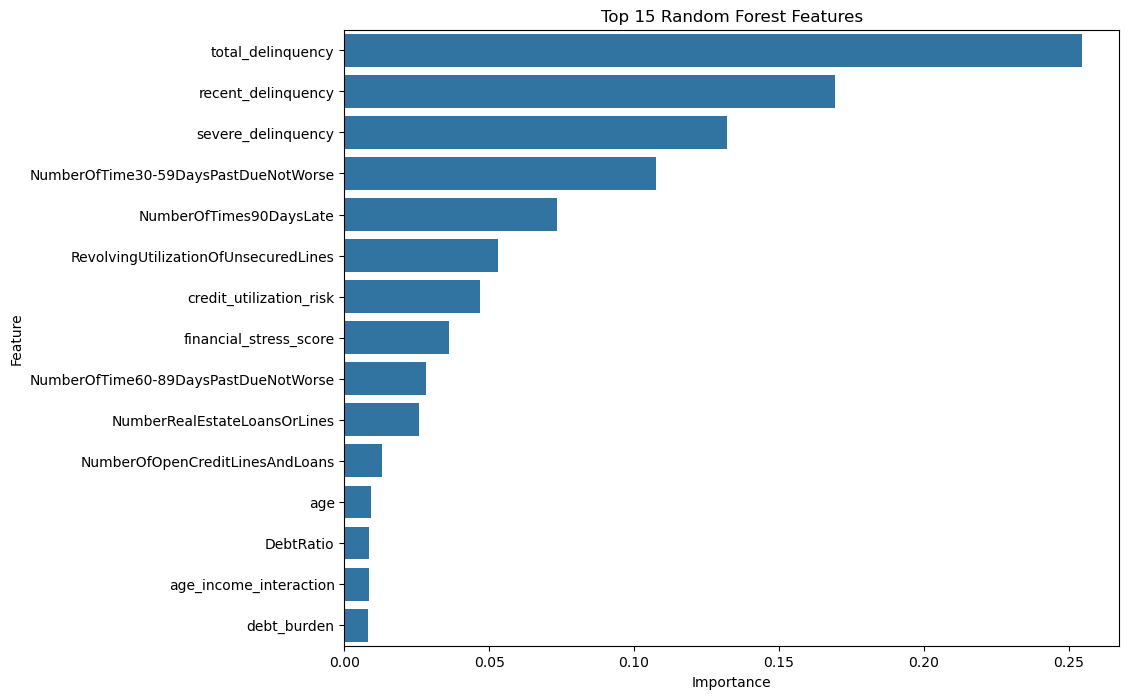

In [43]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Random Forest Features"
)

plt.show()


In [44]:
xgb_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

display(
    xgb_importance
)

,Feature,Importance
11,total_delinquency,0.377030
12,severe_delinquency,0.139138
7,NumberOfTime30-59DaysPastDueNotWorse,0.111676
13,recent_delinquency,0.079357
6,NumberRealEstateLoansOrLines,0.052178
5,NumberOfTimes90DaysLate,0.046756
14,credit_utilization_risk,0.038986
4,NumberOfOpenCreditLinesAndLoans,0.033508
0,RevolvingUtilizationOfUnsecuredLines,0.029249
8,NumberOfTime60-89DaysPastDueNotWorse,0.021417


In [45]:
best_model_name = results.iloc[0]["Model"]

print("Best model:", best_model_name)

Best model: XGBoost


In [46]:
if best_model_name == "Logistic Regression":

    best_predictions = lr_predictions
    best_probabilities = lr_probabilities

elif best_model_name == "Random Forest":

    best_predictions = rf_predictions
    best_probabilities = rf_probabilities

else:

    best_predictions = xgb_predictions
    best_probabilities = xgb_probabilities
    

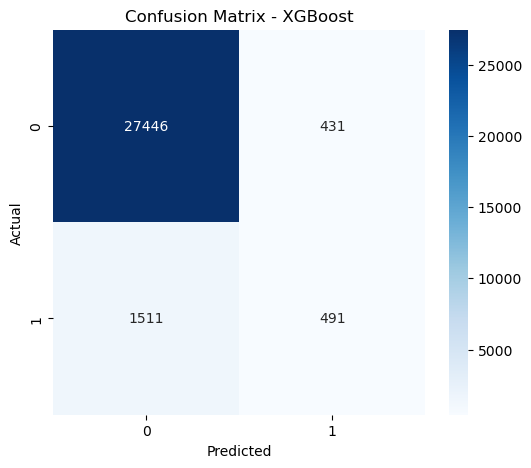

In [47]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

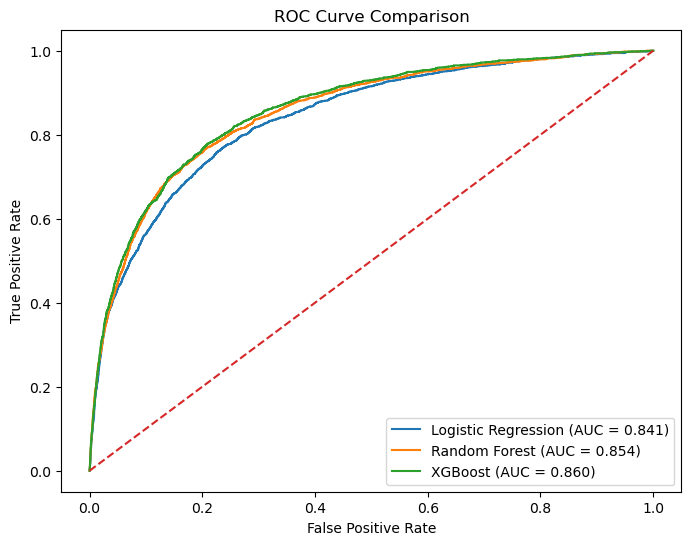

In [48]:
plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Logistic Regression", lr_probabilities),
    ("Random Forest", rf_probabilities),
    ("XGBoost", xgb_probabilities)
]:

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

In [49]:
risk_probability = best_probabilities * 100

risk_results = pd.DataFrame({
    "Actual": y_test.values,
    "Risk_Probability": risk_probability,
    "Predicted_Risk": best_predictions
})

display(
    risk_results.head(20)
)

,Actual,Risk_Probability,Predicted_Risk
0,0,1.051334,0
1,0,38.533928,0
2,0,0.580520,0
3,0,6.827904,0
4,0,8.271156,0
5,0,0.998301,0
6,0,0.823439,0
7,1,19.912336,0
8,0,13.849187,0
9,0,1.599714,0


In [50]:
def risk_category(probability):

    if probability < 30:
        return "LOW RISK"

    elif probability < 60:
        return "MEDIUM RISK"

    else:
        return "HIGH RISK"


risk_results["Risk_Category"] = (
    risk_results["Risk_Probability"]
    .apply(risk_category)
)

display(
    risk_results.head(20)
)

,Actual,Risk_Probability,Predicted_Risk,Risk_Category
0,0,1.051334,0,LOW RISK
1,0,38.533928,0,MEDIUM RISK
2,0,0.580520,0,LOW RISK
3,0,6.827904,0,LOW RISK
4,0,8.271156,0,LOW RISK
5,0,0.998301,0,LOW RISK
6,0,0.823439,0,LOW RISK
7,1,19.912336,0,LOW RISK
8,0,13.849187,0,LOW RISK
9,0,1.599714,0,LOW RISK


In [51]:
import joblib

if best_model_name == "Random Forest":

    best_model = rf_model

elif best_model_name == "XGBoost":

    best_model = xgb_model

else:

    best_model = logistic_model


joblib.dump(
    best_model,
    "paylater_best_model.pkl"
)

joblib.dump(
    imputer,
    "paylater_imputer.pkl"
)

joblib.dump(
    scaler,
    "paylater_scaler.pkl"
)

joblib.dump(
    FEATURES,
    "paylater_features.pkl"
)

print("Model files saved successfully!")


Model files saved successfully!


In [55]:
import os

print("Current notebook directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())

Current notebook directory:
C:\Users\VICTUS\OneDrive\Documents\PL

Files in this directory:
['.ipynb_checkpoints', 'cs-training.csv', 'paylater_best_model.pkl', 'paylater_features.pkl', 'paylater_imputer.pkl', 'paylater_scaler.pkl', 'Untitled.ipynb']
